# Day 2 practical — From Cell Ranger counts to cell types 🧬
**Single-cell RNA-seq analysis in Python**

**Today’s learning objectives:** load a count matrix, inspect an `AnnData` object, check cell quality, normalize expression, calculate PCA/UMAP, cluster cells, and explore marker genes.

**Workflow:** Count matrix → QC → Filter → Normalize → PCA → Neighbors → UMAP → Leiden clusters → Marker genes.

**How to use:** We use the public PBMC3k dataset by default, so you do **not** need to upload files. You can optionally use your own Cell Ranger `filtered_feature_bc_matrix.h5` from Day 1.

*Teaching note:* QC thresholds are illustrative, not universal. For research, inspect distributions and decide thresholds for each experiment.

## 1. Setup and load data

**Scanpy** provides analysis tools for single-cell gene-expression data. **AnnData** stores a matrix of cells × genes plus annotations. The first code cell can take a couple of minutes on a fresh Colab runtime.

In [1]:
!pip install -q "pandas==2.2.3" "scanpy[leiden]==1.11.5"

In [2]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from importlib.metadata import version

sc.settings.set_figure_params(dpi=90, facecolor="white")
print("Scanpy version:", version("scanpy"))

Scanpy version: 1.11.5


In [3]:
# 3k PBMCs from a Healthy Donor, freely available from 10x Genomics
adata = sc.datasets.pbmc3k()
# Some genes have the same gene symbol, even though they have different Ensembl gene IDs
adata.var_names_make_unique()
print(adata)

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'


In [4]:
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)
print("First five gene names:", adata.var_names[:5].tolist())
print("First five cell names:", adata.obs_names[:5].tolist())

Number of cells: 2700
Number of genes: 32738
First five gene names: ['MIR1302-10', 'FAM138A', 'OR4F5', 'RP11-34P13.7', 'RP11-34P13.8']
First five cell names: ['AAACATACAACCAC-1', 'AAACATTGAGCTAC-1', 'AAACATTGATCAGC-1', 'AAACCGTGCTTCCG-1', 'AAACCGTGTATGCG-1']


## 2. Quality control

Cells with few detected genes may be empty droplets or damaged cells. A very high mitochondrial read fraction can indicate stressed or damaged cells (depending on tissue and protocol). QC helps us inspect these patterns before analysis.

A gene starting with **MT-** is annotated as mitochondrial in these human reference gene names.

In [5]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True, )
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


In [6]:
adata.obs.head()

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt
index,,,,
AAACATACAACCAC-1,781,2421.0,73.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,186.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,28.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,46.0,1.743085
AAACCGTGTATGCG-1,522,981.0,12.0,1.223242


In [7]:
adata.var.head()

,gene_ids,mt,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
index,,,,,,
MIR1302-10,ENSG00000243485,False,0,0.0,100.0,0.0
FAM138A,ENSG00000237613,False,0,0.0,100.0,0.0
OR4F5,ENSG00000186092,False,0,0.0,100.0,0.0
RP11-34P13.7,ENSG00000238009,False,0,0.0,100.0,0.0
RP11-34P13.8,ENSG00000239945,False,0,0.0,100.0,0.0


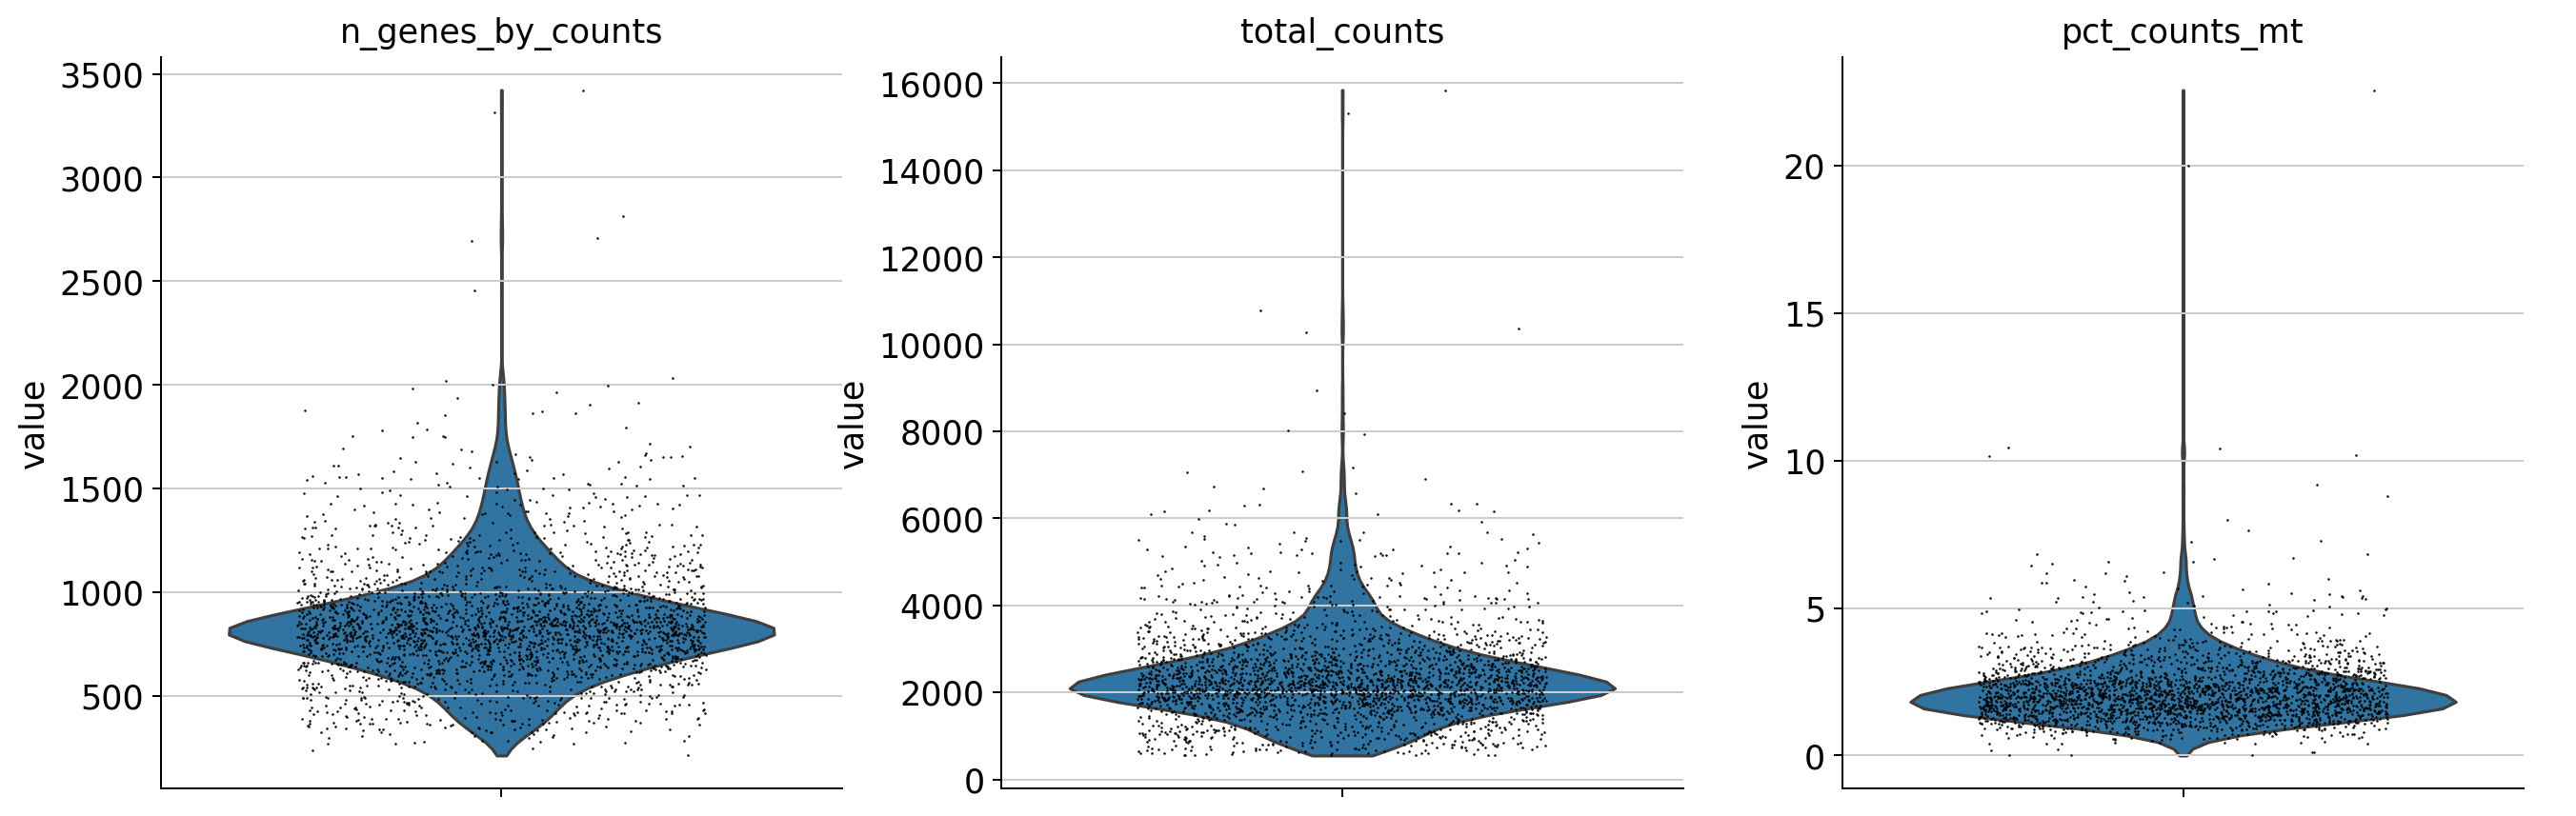

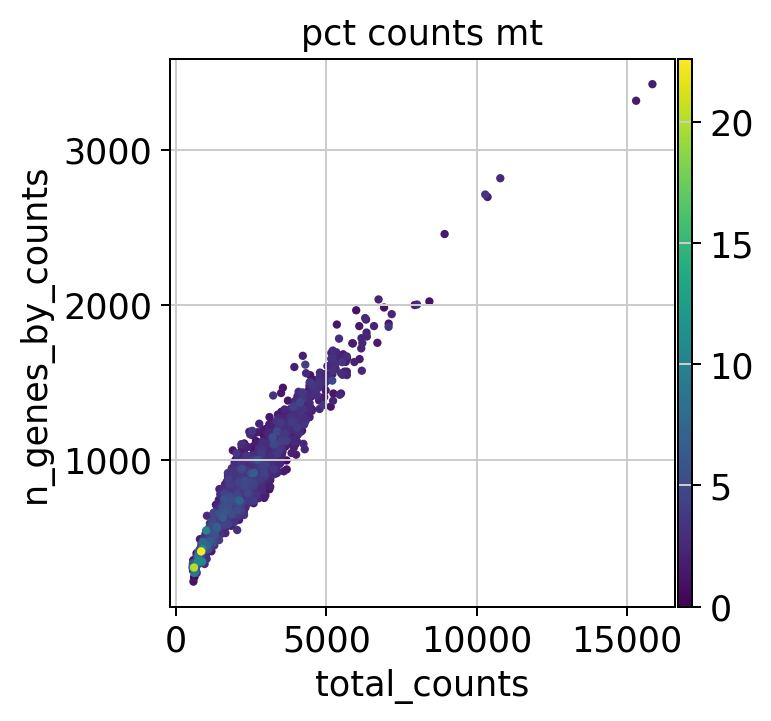

In [8]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.3, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

For this teaching exercise, we remove cells with fewer than 200 detected genes or more than 20% mitochondrial counts, plus genes found in fewer than 3 cells. **These are example cutoffs, not diagnostic standards.**

In [9]:
cells_before, genes_before = adata.shape
sc.pp.filter_cells(adata, min_genes=200)
adata = adata[adata.obs["pct_counts_mt"] < 20].copy()
sc.pp.filter_genes(adata, min_cells=3)

print(f"Cells: {cells_before:,} → {adata.n_obs:,}")
print(f"Genes: {genes_before:,} → {adata.n_vars:,}")

Cells: 2,700 → 2,698
Genes: 32,738 → 13,714


## 3. Normalize and select informative genes

Cells differ in the total number of captured RNA molecules. **Library-size normalization** makes cells more comparable. `log1p` compresses large values. Highly variable genes (HVGs) are selected because they carry information about differences among cells.


In [10]:
# Preserve original counts
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()  # Keep the log-normalized expression of all remaining genes



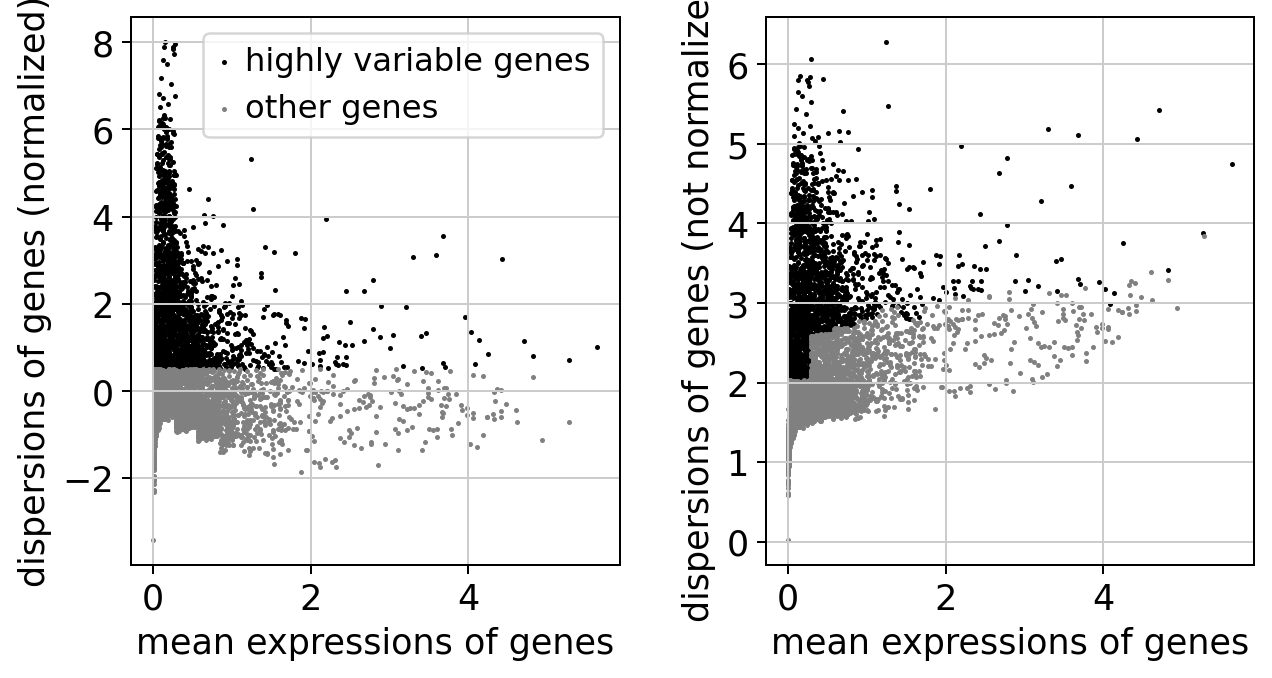

Selected HVGs: 2000


In [11]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat")

sc.pl.highly_variable_genes(adata) #optional - to see the result of HVG
print("Selected HVGs:", int(adata.var["highly_variable"].sum()))

## 4. PCA, neighbors, and UMAP

**PCA** summarizes major patterns of variation; a **neighbor graph** connects cells with similar gene-expression profiles; **UMAP** displays those relationships in two dimensions.

**Important:** UMAP axes are not biological coordinates. Visually separated groups are *suggestive* of distinct populations, not proof of specific cell types.

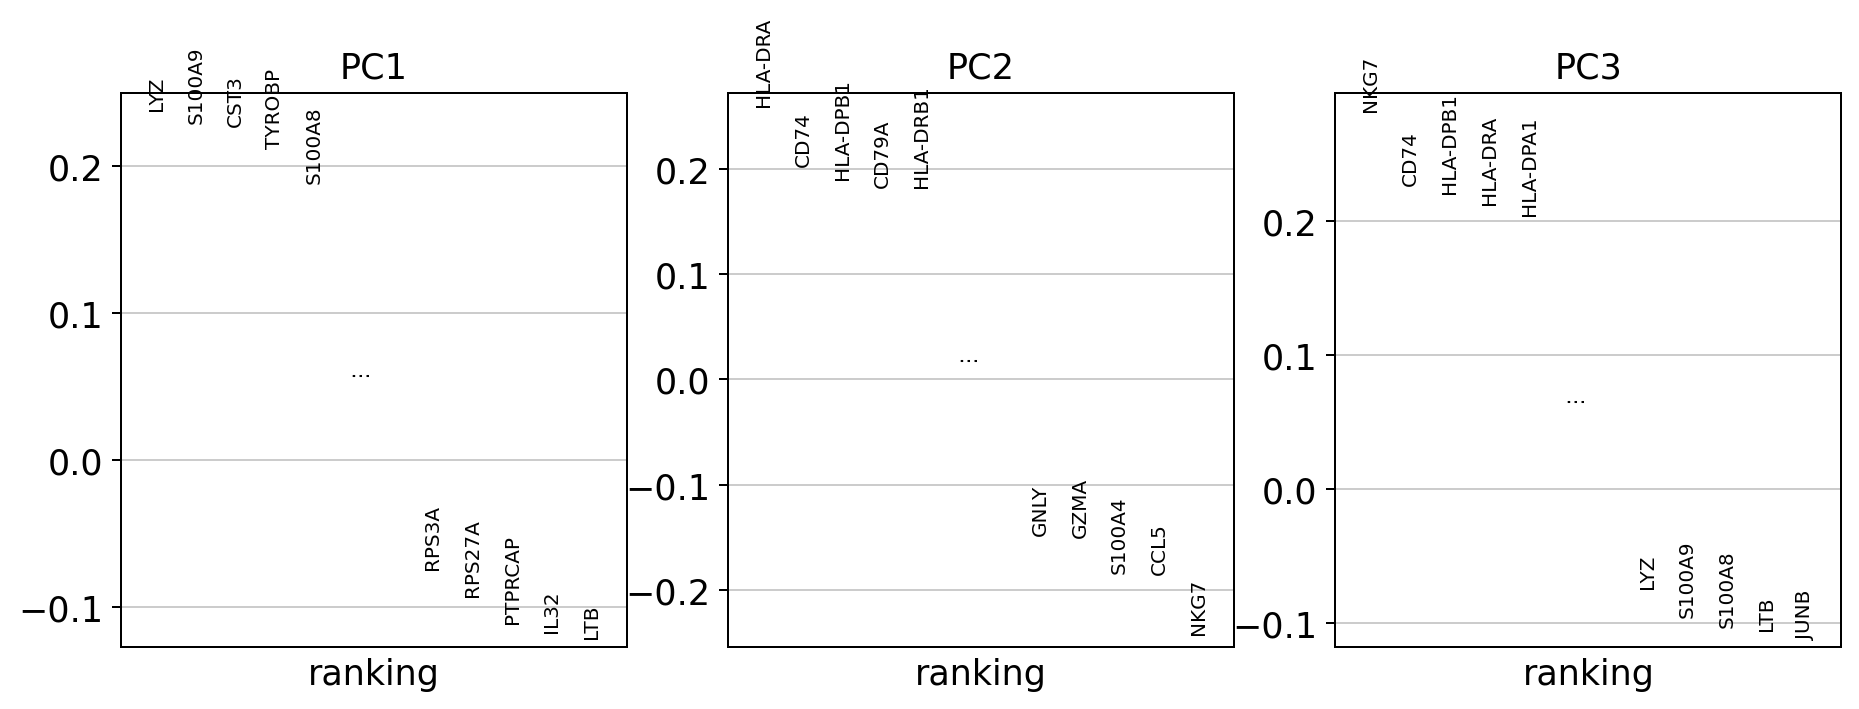

In [12]:
# Create a new AnnData object containing only highly variable genes (HVGs), while keeping all cells
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.tl.pca(adata_hvg)
sc.pl.pca_loadings(adata_hvg, n_points=10) #optional - to see which genes contribute to each PC

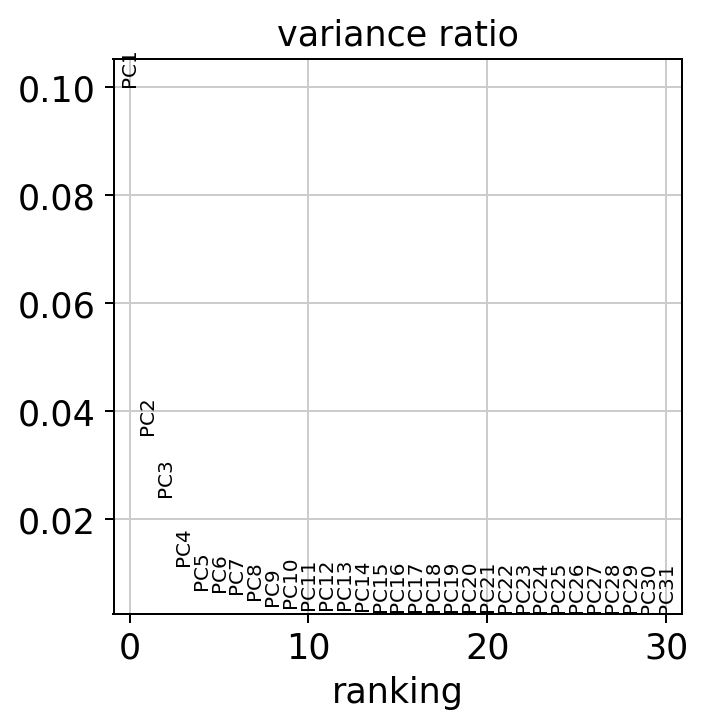

In [13]:
# Plot the percentage of total variance explained by each of the first 30 PCs
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30)

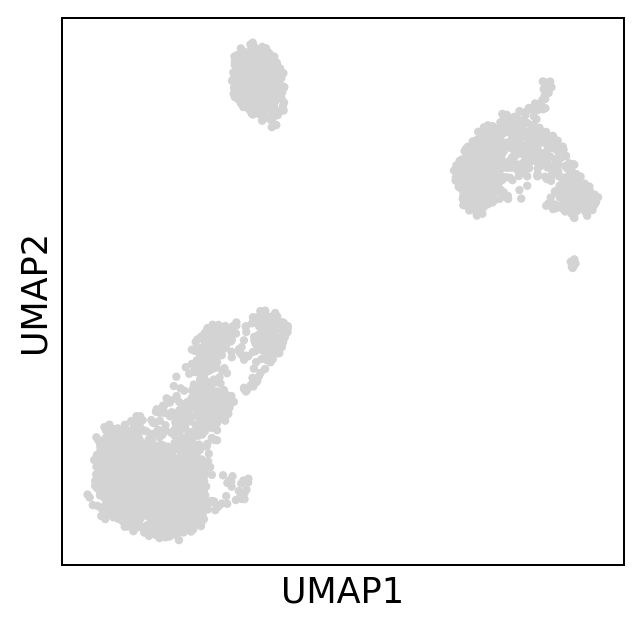

In [14]:
# Construct a network of similar cells
sc.pp.neighbors(adata_hvg, n_neighbors=10, n_pcs=30)
sc.tl.umap(adata_hvg, random_state=0 )
sc.pl.umap(adata_hvg)

**Exercise:** Try different number of neighbors and assess the umap and clustering results.

Other parameters of UMAP calculation:
- min_dist: How tightly cells are packed together (unlike n_neighbors, it doesn't affect the nearest-neighbor graph).
- spread: Controls the scale at which UMAP distributes points in the embedding.
- random_state: UMAP involves stochastic optimization, meaning that different runs may produce somewhat different arrangements. Setting a random seed makes the results more reproducible when using the same data, software environment, and settings.
- n_components: number of dimensions. You can produce 3D embedding by assigning 3 to this parameter.

**Exercise:** Change these parameters and see how your UMAP plot changes.

## 5. Clustering

Leiden clustering finds groups of cells that are strongly connected in the neighborhood graph. The `resolution` parameter controls how fine-grained the grouping is. Cluster labels such as 0, 1, and 2 are **arbitrary identifiers**, not cell-type names.

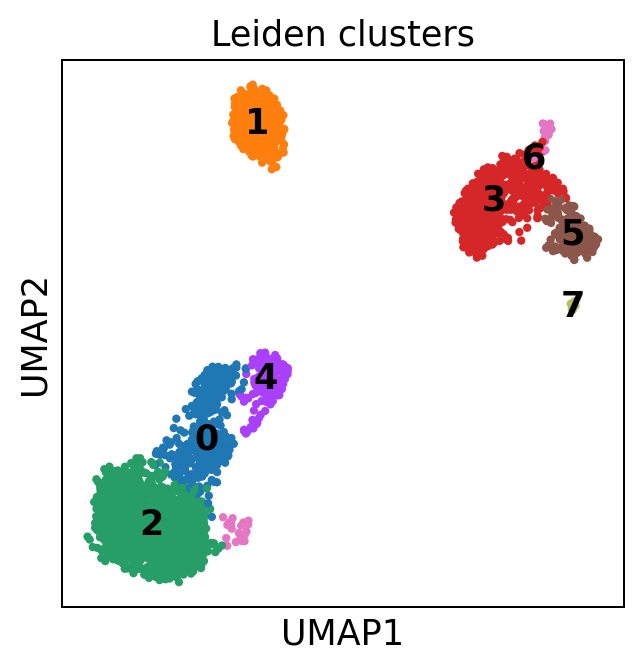

Number of clusters: 8


In [15]:
sc.tl.leiden(adata_hvg, resolution=0.5, key_added="leiden", flavor="igraph", directed=False )
sc.pl.umap(adata_hvg, color="leiden", legend_loc="on data", title="Leiden clusters")
print("Number of clusters:", adata_hvg.obs["leiden"].nunique())

**Exercise:**
- Try different resolutions (commonly between 0 to 2) and visualise the results.
- Restrict the clustering to a specific cluster by assigning cluster number to the parameter "restrict_to":

sc.tl.leiden(
    adata_hvg,
    resolution=0.5,
    restrict_to=("leiden", ["2"]),
    key_added="leiden_sub"
)


## 6. Marker genes and cell identities

To interpret clusters, look for genes expressed more strongly in one cluster than in others, then compare with known immune-cell markers. This notebook demonstrates a quick, exploratory ranking; it does **not** establish cell identities automatically.

Examples: `CD3D` (T cells), `MS4A1` (B cells), `NKG7` (NK/cytotoxic populations), `LYZ` (myeloid cells), `FCGR3A` (some monocytes/NK cells). None of these markers is perfectly specific in isolation.

In [ ]:
# Use log-normalized full-gene data, with cluster assignments from the HVG analysis
adata.obs["leiden"] = adata_hvg.obs["leiden"].copy()
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", use_raw=True)
sc.pl.rank_genes_groups_dotplot(adata, n_genes=10, standard_scale="var", figsize=(22, 6)) # standard scale: normalize each gene to range from 0 to 1

In [ ]:
marker_genes = {
    "CD4 T cells": ["IL7R", "CCR7"],
    "CD8 T cells": ["CD8A", "CD8B"],
    "B cells": ["MS4A1", "CD79A"],
    "NK cells": ["GNLY", "NKG7"],
    "CD14 Monocytes": ["CD14", "LYZ"],
    "FCGR3A Monocytes": ["FCGR3A", "MS4A7"],
    "Dendritic cells": ["FCER1A", "CST3"],
    "Megakaryocytes": ["PPBP", "PF4"]
}

sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby="leiden",
    standard_scale="var"
)

In [ ]:
sc.pl.umap(adata_hvg, color=["IL7R", "CD8A", "MS4A1", "GNLY", "CD14", "FCGR3A", "FCER1A", "PPBP"])